In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import pandas as pd
from pathlib import Path

# Find Excel file in Jupyter's current folder
excel_files = list(Path.cwd().glob("B2B_Transaction_Data_.xlsx"))

print("Files found:", excel_files)

# Load dataset
df = pd.read_excel(
    excel_files[0],
    engine="calamine",
    dtype={
        "InvoiceNo": "string",
        "CustomerID": "string",
        "StockCode": "string"
    }
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Files found: [PosixPath('/Users/bahartamturk/B2B_Transaction_Data_.xlsx')]
Dataset loaded successfully!
Dataset Shape: (664154, 10)


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
0,BSR202000000027,A02348,2020-01-02,8698543133198,Anatolian Puzzle Dünya Siyasi Harita (3319),1000 Parça Puzzle,ISTANBUL,1.00,18.92,22.80
1,BSR202000000007,A02212,2020-01-02,8698543110793,Anatolian-Puzzle 1000 Kurt Timi,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
2,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
3,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
4,BAD202000000028,A00905,2020-01-02,8698543110335,Gezegenler (Puzzle 1000) 1033,1000 Parça Puzzle,AYDIN,1.00,29.84,37.30


In [3]:

# Dataset information
print("DATASET INFORMATION")
df.info()

# Missing values
print("\nMISSING VALUES")
display(pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}))

# Duplicate observations
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
display(df.describe(include="all").T)


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 664154 entries, 0 to 664153
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    664154 non-null  string 
 1   CustomerID   664154 non-null  string 
 2   InvoiceDate  664154 non-null  str    
 3   StockCode    664154 non-null  string 
 4   Description  664154 non-null  object 
 5   Category     664090 non-null  str    
 6   City         657352 non-null  str    
 7   Quantity     664148 non-null  float64
 8   NetPrice     664154 non-null  float64
 9   UnitPrice    664154 non-null  float64
dtypes: float64(3), object(1), str(3), string(3)
memory usage: 93.2+ MB

MISSING VALUES


,Missing Count,Missing Percentage
InvoiceNo,0,0.00
CustomerID,0,0.00
InvoiceDate,0,0.00
StockCode,0,0.00
Description,0,0.00
Category,64,0.01
City,6802,1.02
Quantity,6,0.00
NetPrice,0,0.00
UnitPrice,0,0.00



DUPLICATE ROWS
6213

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,664154,47471,DPF202000002142,3246,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerID,664154,1202,A02348,32908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InvoiceDate,664154,286,2020-10-22,6624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,664154,43578,9786058422841,1363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,664154,41196,Dedemin Bakkalı,1363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,664090,306,Roman/Öykü,67739,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,657352,77,ISTANBUL,340501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"664,148.00",NaN,NaN,NaN,2.84,13.38,0.00,1.00,1.00,2.00,"3,000.00"
NetPrice,"664,154.00",NaN,NaN,NaN,16.63,10.79,-358.80,9.92,15.00,21.00,"1,618.50"
UnitPrice,"664,154.00",NaN,NaN,NaN,26.92,17.21,0.00,16.00,25.00,34.00,"2,490.00"


In [4]:

# Check invalid numerical values
for col in ["Quantity", "NetPrice", "UnitPrice"]:
    values = pd.to_numeric(df[col], errors="coerce")

    print(f"\n{col}")
    print("Negative:", (values < 0).sum())
    print("Zero:", (values == 0).sum())
    print("Missing:", values.isna().sum())

# Check date range
dates = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

print("\nDATE RANGE")
print("Min:", dates.min())
print("Max:", dates.max())
print("Invalid Dates:", dates.isna().sum())



Quantity
Negative: 0
Zero: 5
Missing: 6

NetPrice
Negative: 5
Zero: 5
Missing: 0

UnitPrice
Negative: 0
Zero: 0
Missing: 0

DATE RANGE
Min: 2020-01-02 00:00:00
Max: 2020-12-31 00:00:00
Invalid Dates: 0


In [5]:

# Inspect suspicious records before cleaning

print("ROWS WITH INVALID QUANTITY")
display(
    df[df["Quantity"].isna() | (df["Quantity"] <= 0)]
)

print("ROWS WITH NON-POSITIVE NET PRICE")
display(
    df[df["NetPrice"] <= 0]
)

print("SAMPLE EXACT DUPLICATES")
display(
    df[df.duplicated(keep=False)]
    .sort_values(["InvoiceNo", "StockCode"])
    .head(20)
)

print("PRICE RELATIONSHIP")
display(
    df[["Quantity", "NetPrice", "UnitPrice"]]
    .sample(15, random_state=42)
)


ROWS WITH INVALID QUANTITY


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
96974,BAD202000005042,A02104,2020-02-12,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,KIRSEHIR,NaN,1.00,17.00
225119,BAD202000010877,A01759,2020-05-04,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ISTANBUL,NaN,1.00,17.00
355002,DPE202000000733,A02346,2020-08-18,9786050957372,Vahşi Şeyler,Çocuk Öykü/Hikaye,ANKARA,0.00,-204.93,204.93
355623,DPE202000000733,A02346,2020-08-18,9786050930610,Gıdıklanan Kitap,Roman/Öykü,ANKARA,0.00,-358.80,358.80
417758,BAD202000019093,A01124,2020-09-24,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ISTANBUL,NaN,1.00,17.00
509961,BAD202000023484,A00284,2020-11-02,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ADANA,NaN,2.00,18.70
585953,BSR202000016862,A00762,2020-12-02,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ORDU,NaN,2.00,18.70
655496,BAD202000029451,P01233,2020-12-30,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ISTANBUL,NaN,1.00,18.70
657318,DPF202000002743,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-122.00,122.00
657319,DPF202000002744,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-61.00,61.00


ROWS WITH NON-POSITIVE NET PRICE


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
223264,DPF202000000803,A00233,2020-04-29,9789754370430,Beyaz Gemi,Dünya Roman,ISTANBUL,28.00,0.00,0.00
223322,DPF202000000803,A00233,2020-04-29,9789754371543,Toprak Ana,Dünya Roman,ISTANBUL,28.00,0.00,0.00
252735,DPF202000000875,A00233,2020-05-22,9789752473218,Sol Ayağım,Dünya Roman,ISTANBUL,28.00,0.00,0.00
355002,DPE202000000733,A02346,2020-08-18,9786050957372,Vahşi Şeyler,Çocuk Öykü/Hikaye,ANKARA,0.00,-204.93,204.93
355623,DPE202000000733,A02346,2020-08-18,9786050930610,Gıdıklanan Kitap,Roman/Öykü,ANKARA,0.00,-358.80,358.80
391796,DPE202000000808,P00569,2020-09-11,9786051068275,Dinler Kitabı,Din,ISTANBUL,1.00,0.00,0.00
590677,DPE202000001120,P00569,2020-12-03,9786052950319,Ağaç Evinde Tatil (Ciltli),Masal & Hikaye Kitapları,ISTANBUL,1.00,0.00,55.56
657318,DPF202000002743,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-122.00,122.00
657319,DPF202000002744,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-61.00,61.00
657785,DPF202000002744,S00032,2020-12-30,9789753423472,Yüzüklerin Efendisi (Tek Cilt),Fantastik,ISTANBUL,0.00,-159.21,159.21


SAMPLE EXACT DUPLICATES


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
45,BAD202000000047,A01086,2020-01-02,9786053845317,Çocuğunuza Sınır Koyma 1,Aile - Çocuk,ADANA,2.00,15.00,30.00
46,BAD202000000047,A01086,2020-01-02,9786053845317,Çocuğunuza Sınır Koyma 1,Aile - Çocuk,ADANA,2.00,15.00,30.00
1109,BAD202000000047,A01086,2020-01-02,9789754371543,Toprak Ana,Dünya Roman,ADANA,5.00,5.40,9.00
1110,BAD202000000047,A01086,2020-01-02,9789754371543,Toprak Ana,Dünya Roman,ADANA,5.00,5.40,9.00
3148,BAD202000000095,A00304,2020-01-02,9789750726248,Tatarcık,Türkiye Roman,ISTANBUL,1.00,17.05,27.50
3149,BAD202000000095,A00304,2020-01-02,9789750726248,Tatarcık,Türkiye Roman,ISTANBUL,1.00,17.05,27.50
101,BAD202000000102,A01530,2020-01-02,9786056700804,Gerçek Tıp,Beden Sağlığı,KOCAELI,1.00,39.00,60.00
102,BAD202000000102,A01530,2020-01-02,9786056700804,Gerçek Tıp,Beden Sağlığı,KOCAELI,1.00,39.00,60.00
6362,BAD202000000108,A00253,2020-01-03,9789750735639,Anayurt Oteli,Türkiye Roman,ISTANBUL,2.00,8.68,14.00
6363,BAD202000000108,A00253,2020-01-03,9789750735639,Anayurt Oteli,Türkiye Roman,ISTANBUL,2.00,8.68,14.00


PRICE RELATIONSHIP


,Quantity,NetPrice,UnitPrice
609816,1.00,15.86,26.00
372310,2.00,35.20,64.00
28487,5.00,15.00,25.00
305100,1.00,15.55,25.50
8844,1.00,23.40,36.00
209500,2.00,12.73,19.00
638730,1.00,11.30,18.52
27922,5.00,6.60,11.00
50490,1.00,14.08,22.00
650444,2.00,18.20,28.00


In [6]:

# Create a copy to preserve the raw dataset
df_clean = df.copy()

# 1. Convert dates
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# 2. Convert numerical columns
numeric_cols = ["Quantity", "NetPrice", "UnitPrice"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# 3. Clean categorical columns
text_cols = ["Category", "City", "Description"]

for col in text_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

# 4. Standardize city and category
df_clean["City"] = df_clean["City"].str.upper()
df_clean["City"] = df_clean["City"].fillna("UNKNOWN")
df_clean["Category"] = df_clean["Category"].fillna("Unknown")

# 5. Remove rows with missing or zero quantity
df_clean = df_clean[
    df_clean["Quantity"].notna()
    & (df_clean["Quantity"] > 0)
].copy()

# 6. Remove negative net prices
# These require separate investigation and are excluded
# from the main sales dataset.
df_clean = df_clean[
    df_clean["NetPrice"] >= 0
].copy()

# 7. Remove invalid dates
df_clean = df_clean[
    df_clean["InvoiceDate"].notna()
].copy()

# 8. Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))


Original rows: 664154
Cleaned rows: 664143
Removed rows: 11


In [7]:

print("CLEANED DATA QUALITY REPORT")

print("\nShape:", df_clean.shape)

print("\nMissing Values:")
display(df_clean.isna().sum())

print("\nQuantity Summary:")
display(df_clean["Quantity"].describe())

print("\nNet Price Summary:")
display(df_clean["NetPrice"].describe())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

display(df_clean.head())


CLEANED DATA QUALITY REPORT

Shape: (664143, 10)

Missing Values:


InvoiceNo      0
CustomerID     0
InvoiceDate    0
StockCode      0
Description    0
Category       0
City           0
Quantity       0
NetPrice       0
UnitPrice      0
dtype: int64


Quantity Summary:


count   664,143.00
mean          2.84
std          13.38
min           1.00
25%           1.00
50%           1.00
75%           2.00
max       3,000.00
Name: Quantity, dtype: float64


Net Price Summary:


count   664,143.00
mean         16.63
std          10.77
min           0.00
25%           9.92
50%          15.00
75%          21.00
max       1,618.50
Name: NetPrice, dtype: float64


Duplicate Rows:
6213


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
0,BSR202000000027,A02348,2020-01-02,8698543133198,Anatolian Puzzle Dünya Siyasi Harita (3319),1000 Parça Puzzle,ISTANBUL,1.00,18.92,22.80
1,BSR202000000007,A02212,2020-01-02,8698543110793,Anatolian-Puzzle 1000 Kurt Timi,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
2,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
3,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
4,BAD202000000028,A00905,2020-01-02,8698543110335,Gezegenler (Puzzle 1000) 1033,1000 Parça Puzzle,AYDIN,1.00,29.84,37.30


In [8]:

# Inspect suspicious records before cleaning

print("ROWS WITH INVALID QUANTITY")
display(
    df[df["Quantity"].isna() | (df["Quantity"] <= 0)]
)

print("ROWS WITH NON-POSITIVE NET PRICE")
display(
    df[df["NetPrice"] <= 0]
)

print("SAMPLE EXACT DUPLICATES")
display(
    df[df.duplicated(keep=False)]
    .sort_values(["InvoiceNo", "StockCode"])
    .head(20)
)

print("PRICE RELATIONSHIP")
display(
    df[["Quantity", "NetPrice", "UnitPrice"]]
    .sample(15, random_state=42)
)


ROWS WITH INVALID QUANTITY


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
96974,BAD202000005042,A02104,2020-02-12,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,KIRSEHIR,NaN,1.00,17.00
225119,BAD202000010877,A01759,2020-05-04,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ISTANBUL,NaN,1.00,17.00
355002,DPE202000000733,A02346,2020-08-18,9786050957372,Vahşi Şeyler,Çocuk Öykü/Hikaye,ANKARA,0.00,-204.93,204.93
355623,DPE202000000733,A02346,2020-08-18,9786050930610,Gıdıklanan Kitap,Roman/Öykü,ANKARA,0.00,-358.80,358.80
417758,BAD202000019093,A01124,2020-09-24,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ISTANBUL,NaN,1.00,17.00
509961,BAD202000023484,A00284,2020-11-02,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ADANA,NaN,2.00,18.70
585953,BSR202000016862,A00762,2020-12-02,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ORDU,NaN,2.00,18.70
655496,BAD202000029451,P01233,2020-12-30,9789751419149,Saygılı Anne-Baba,Aile - Çocuk,ISTANBUL,NaN,1.00,18.70
657318,DPF202000002743,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-122.00,122.00
657319,DPF202000002744,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-61.00,61.00


ROWS WITH NON-POSITIVE NET PRICE


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
223264,DPF202000000803,A00233,2020-04-29,9789754370430,Beyaz Gemi,Dünya Roman,ISTANBUL,28.00,0.00,0.00
223322,DPF202000000803,A00233,2020-04-29,9789754371543,Toprak Ana,Dünya Roman,ISTANBUL,28.00,0.00,0.00
252735,DPF202000000875,A00233,2020-05-22,9789752473218,Sol Ayağım,Dünya Roman,ISTANBUL,28.00,0.00,0.00
355002,DPE202000000733,A02346,2020-08-18,9786050957372,Vahşi Şeyler,Çocuk Öykü/Hikaye,ANKARA,0.00,-204.93,204.93
355623,DPE202000000733,A02346,2020-08-18,9786050930610,Gıdıklanan Kitap,Roman/Öykü,ANKARA,0.00,-358.80,358.80
391796,DPE202000000808,P00569,2020-09-11,9786051068275,Dinler Kitabı,Din,ISTANBUL,1.00,0.00,0.00
590677,DPE202000001120,P00569,2020-12-03,9786052950319,Ağaç Evinde Tatil (Ciltli),Masal & Hikaye Kitapları,ISTANBUL,1.00,0.00,55.56
657318,DPF202000002743,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-122.00,122.00
657319,DPF202000002744,S00032,2020-12-30,9789753424080,Sana Gül Bahçesi Vadetmedim,Dünya Roman,ISTANBUL,0.00,-61.00,61.00
657785,DPF202000002744,S00032,2020-12-30,9789753423472,Yüzüklerin Efendisi (Tek Cilt),Fantastik,ISTANBUL,0.00,-159.21,159.21


SAMPLE EXACT DUPLICATES


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
45,BAD202000000047,A01086,2020-01-02,9786053845317,Çocuğunuza Sınır Koyma 1,Aile - Çocuk,ADANA,2.00,15.00,30.00
46,BAD202000000047,A01086,2020-01-02,9786053845317,Çocuğunuza Sınır Koyma 1,Aile - Çocuk,ADANA,2.00,15.00,30.00
1109,BAD202000000047,A01086,2020-01-02,9789754371543,Toprak Ana,Dünya Roman,ADANA,5.00,5.40,9.00
1110,BAD202000000047,A01086,2020-01-02,9789754371543,Toprak Ana,Dünya Roman,ADANA,5.00,5.40,9.00
3148,BAD202000000095,A00304,2020-01-02,9789750726248,Tatarcık,Türkiye Roman,ISTANBUL,1.00,17.05,27.50
3149,BAD202000000095,A00304,2020-01-02,9789750726248,Tatarcık,Türkiye Roman,ISTANBUL,1.00,17.05,27.50
101,BAD202000000102,A01530,2020-01-02,9786056700804,Gerçek Tıp,Beden Sağlığı,KOCAELI,1.00,39.00,60.00
102,BAD202000000102,A01530,2020-01-02,9786056700804,Gerçek Tıp,Beden Sağlığı,KOCAELI,1.00,39.00,60.00
6362,BAD202000000108,A00253,2020-01-03,9789750735639,Anayurt Oteli,Türkiye Roman,ISTANBUL,2.00,8.68,14.00
6363,BAD202000000108,A00253,2020-01-03,9789750735639,Anayurt Oteli,Türkiye Roman,ISTANBUL,2.00,8.68,14.00


PRICE RELATIONSHIP


,Quantity,NetPrice,UnitPrice
609816,1.00,15.86,26.00
372310,2.00,35.20,64.00
28487,5.00,15.00,25.00
305100,1.00,15.55,25.50
8844,1.00,23.40,36.00
209500,2.00,12.73,19.00
638730,1.00,11.30,18.52
27922,5.00,6.60,11.00
50490,1.00,14.08,22.00
650444,2.00,18.20,28.00


In [9]:

# Create a copy to preserve the raw dataset
df_clean = df.copy()

# 1. Convert dates
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# 2. Convert numerical columns
numeric_cols = ["Quantity", "NetPrice", "UnitPrice"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# 3. Clean categorical columns
text_cols = ["Category", "City", "Description"]

for col in text_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

# 4. Standardize city and category
df_clean["City"] = df_clean["City"].str.upper()
df_clean["City"] = df_clean["City"].fillna("UNKNOWN")
df_clean["Category"] = df_clean["Category"].fillna("Unknown")

# 5. Remove rows with missing or zero quantity
df_clean = df_clean[
    df_clean["Quantity"].notna()
    & (df_clean["Quantity"] > 0)
].copy()

# 6. Remove negative net prices
# These require separate investigation and are excluded
# from the main sales dataset.
df_clean = df_clean[
    df_clean["NetPrice"] >= 0
].copy()

# 7. Remove invalid dates
df_clean = df_clean[
    df_clean["InvoiceDate"].notna()
].copy()

# 8. Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))


Original rows: 664154
Cleaned rows: 664143
Removed rows: 11


In [10]:

print("CLEANED DATA QUALITY REPORT")

print("\nShape:", df_clean.shape)

print("\nMissing Values:")
display(df_clean.isna().sum())

print("\nQuantity Summary:")
display(df_clean["Quantity"].describe())

print("\nNet Price Summary:")
display(df_clean["NetPrice"].describe())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

display(df_clean.head())


CLEANED DATA QUALITY REPORT

Shape: (664143, 10)

Missing Values:


InvoiceNo      0
CustomerID     0
InvoiceDate    0
StockCode      0
Description    0
Category       0
City           0
Quantity       0
NetPrice       0
UnitPrice      0
dtype: int64


Quantity Summary:


count   664,143.00
mean          2.84
std          13.38
min           1.00
25%           1.00
50%           1.00
75%           2.00
max       3,000.00
Name: Quantity, dtype: float64


Net Price Summary:


count   664,143.00
mean         16.63
std          10.77
min           0.00
25%           9.92
50%          15.00
75%          21.00
max       1,618.50
Name: NetPrice, dtype: float64


Duplicate Rows:
6213


,InvoiceNo,CustomerID,InvoiceDate,StockCode,Description,Category,City,Quantity,NetPrice,UnitPrice
0,BSR202000000027,A02348,2020-01-02,8698543133198,Anatolian Puzzle Dünya Siyasi Harita (3319),1000 Parça Puzzle,ISTANBUL,1.00,18.92,22.80
1,BSR202000000007,A02212,2020-01-02,8698543110793,Anatolian-Puzzle 1000 Kurt Timi,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
2,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
3,BSR202000000019,A02212,2020-01-02,8698543110779,Anatolian-Puzzle 1000 Mustafa Kemal Atatürk,1000 Parça Puzzle,ISTANBUL,1.00,29.84,37.30
4,BAD202000000028,A00905,2020-01-02,8698543110335,Gezegenler (Puzzle 1000) 1033,1000 Parça Puzzle,AYDIN,1.00,29.84,37.30


In [11]:

# Analyze relationship between NetPrice and UnitPrice

price_check = df_clean[
    ["Quantity", "NetPrice", "UnitPrice"]
].copy()

price_check["Net_to_Unit_Ratio"] = (
    price_check["NetPrice"] / price_check["UnitPrice"]
)

print("PRICE RELATIONSHIP ANALYSIS")

print("\nCorrelation Matrix:")
display(
    price_check[
        ["Quantity", "NetPrice", "UnitPrice"]
    ].corr()
)

print("\nPrice Ratio Summary:")
display(
    price_check["Net_to_Unit_Ratio"].describe()
)

print("\nNetPrice > UnitPrice:")
print(
    (price_check["NetPrice"] > price_check["UnitPrice"]).sum()
)

print("\nPrice Comparison by Quantity:")
display(
    price_check.groupby("Quantity")[
        ["NetPrice", "UnitPrice"]
    ].median().head(15)
)


PRICE RELATIONSHIP ANALYSIS

Correlation Matrix:


,Quantity,NetPrice,UnitPrice
Quantity,1.00,-0.02,-0.01
NetPrice,-0.02,1.00,0.99
UnitPrice,-0.01,0.99,1.00



Price Ratio Summary:


count   664,143.00
mean          0.62
std           0.06
min           0.00
25%           0.60
50%           0.62
75%           0.65
max           1.54
Name: Net_to_Unit_Ratio, dtype: float64


NetPrice > UnitPrice:
5

Price Comparison by Quantity:


,NetPrice,UnitPrice
Quantity,,
1.00,15.40,25.00
2.00,15.00,25.00
3.00,14.49,24.00
4.00,14.40,23.00
5.00,13.68,22.00
6.00,13.64,22.00
7.00,13.64,22.00
8.00,14.00,22.00
9.00,13.21,22.00


In [12]:

# Extract time-based features

df_clean["Year"] = df_clean["InvoiceDate"].dt.year

df_clean["Month"] = df_clean["InvoiceDate"].dt.month

df_clean["MonthName"] = df_clean["InvoiceDate"].dt.month_name()

df_clean["Quarter"] = df_clean["InvoiceDate"].dt.quarter

df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()

df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

print("DATE FEATURES CREATED")

display(
    df_clean[
        [
            "InvoiceDate",
            "Year",
            "Month",
            "MonthName",
            "Quarter",
            "DayOfWeek",
            "YearMonth"
        ]
    ].head()
)


DATE FEATURES CREATED


,InvoiceDate,Year,Month,MonthName,Quarter,DayOfWeek,YearMonth
0,2020-01-02,2020,1,January,1,Thursday,2020-01
1,2020-01-02,2020,1,January,1,Thursday,2020-01
2,2020-01-02,2020,1,January,1,Thursday,2020-01
3,2020-01-02,2020,1,January,1,Thursday,2020-01
4,2020-01-02,2020,1,January,1,Thursday,2020-01


In [13]:

# Outlier detection using IQR method

Q1 = df_clean["Quantity"].quantile(0.25)
Q3 = df_clean["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean["QuantityOutlier"] = (
    (df_clean["Quantity"] < lower_bound) |
    (df_clean["Quantity"] > upper_bound)
)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print(
    "Number of Quantity Outliers:",
    df_clean["QuantityOutlier"].sum()
)

print(
    "Outlier Percentage:",
    round(df_clean["QuantityOutlier"].mean() * 100, 2)
)

display(
    df_clean.loc[
        df_clean["QuantityOutlier"],
        ["Quantity", "NetPrice", "UnitPrice"]
    ].describe()
)


Lower Bound: -0.5
Upper Bound: 3.5
Number of Quantity Outliers: 92127
Outlier Percentage: 13.87


,Quantity,NetPrice,UnitPrice
count,"92,127.00","92,127.00","92,127.00"
mean,11.73,15.05,24.79
std,34.58,8.69,14.33
min,4.00,0.00,0.00
25%,5.00,9.12,15.00
50%,5.00,13.75,22.00
75%,10.00,18.76,30.00
max,"3,000.00",235.00,470.00


In [14]:

# Sales Feature Engineering
# Assumption: NetPrice represents discounted unit price.

df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["NetPrice"]
)

df_clean["GrossRevenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean["DiscountAmount"] = (
    df_clean["GrossRevenue"] - df_clean["Revenue"]
)

df_clean["DiscountRate"] = np.where(
    df_clean["GrossRevenue"] > 0,
    df_clean["DiscountAmount"] / df_clean["GrossRevenue"],
    np.nan
)

# Review suspicious discount rates
print("Negative Discount Rates:",
      (df_clean["DiscountRate"] < 0).sum())

print("Discount Rates Above 100%:",
      (df_clean["DiscountRate"] > 1).sum())

print("\nSALES METRICS")

print("Total Revenue:", round(df_clean["Revenue"].sum(), 2))
print("Total Gross Revenue:", round(df_clean["GrossRevenue"].sum(), 2))
print("Total Units Sold:", df_clean["Quantity"].sum())
print("Total Orders:", df_clean["InvoiceNo"].nunique())
print("Total Customers:", df_clean["CustomerID"].nunique())

display(
    df_clean[
        [
            "Quantity",
            "NetPrice",
            "UnitPrice",
            "Revenue",
            "GrossRevenue",
            "DiscountAmount",
            "DiscountRate"
        ]
    ].head(10)
)


Negative Discount Rates: 5
Discount Rates Above 100%: 0

SALES METRICS
Total Revenue: 29579960.23
Total Gross Revenue: 48672918.65
Total Units Sold: 1889193.0
Total Orders: 47468
Total Customers: 1201


,Quantity,NetPrice,UnitPrice,Revenue,GrossRevenue,DiscountAmount,DiscountRate
0,1.00,18.92,22.80,18.92,22.80,3.88,0.17
1,1.00,29.84,37.30,29.84,37.30,7.46,0.20
2,1.00,29.84,37.30,29.84,37.30,7.46,0.20
3,1.00,29.84,37.30,29.84,37.30,7.46,0.20
4,1.00,29.84,37.30,29.84,37.30,7.46,0.20
5,1.00,29.84,37.30,29.84,37.30,7.46,0.20
6,2.00,29.84,37.30,59.68,74.60,14.92,0.20
7,1.00,29.84,37.30,29.84,37.30,7.46,0.20
8,1.00,29.84,37.30,29.84,37.30,7.46,0.20
9,1.00,29.84,37.30,29.84,37.30,7.46,0.20


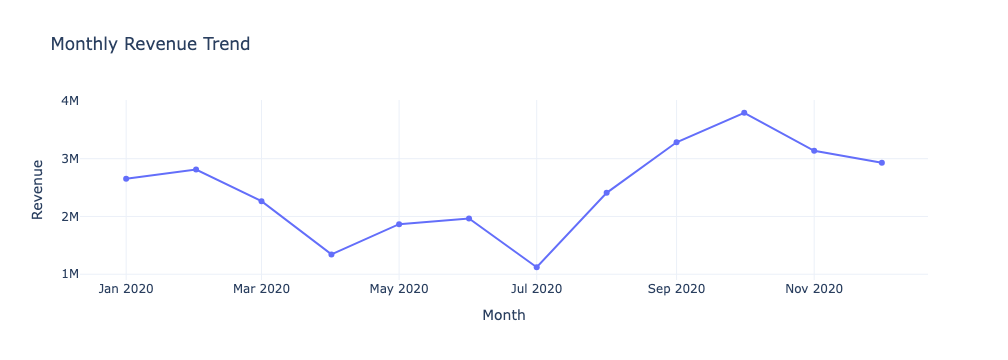

,YearMonth,Revenue,Quantity,Orders
0,2020-01,"2,653,203.77","181,586.00",5291
1,2020-02,"2,812,337.61","191,371.00",5197
2,2020-03,"2,264,196.21","152,435.00",3869
3,2020-04,"1,343,250.30","91,112.00",2055
4,2020-05,"1,866,034.68","115,810.00",1824
5,2020-06,"1,965,711.66","128,275.00",3530
6,2020-07,"1,120,746.26","69,553.00",1589
7,2020-08,"2,408,732.38","158,366.00",3194
8,2020-09,"3,284,012.05","203,499.00",5304
9,2020-10,"3,794,925.81","228,188.00",5566


In [15]:

import plotly.express as px

monthly_sales = (
    df_clean.groupby("YearMonth", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
)

fig = px.line(
    monthly_sales,
    x="YearMonth",
    y="Revenue",
    markers=True,
    title="Monthly Revenue Trend"
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Revenue",
    template="plotly_white"
)

fig.show()

display(monthly_sales)


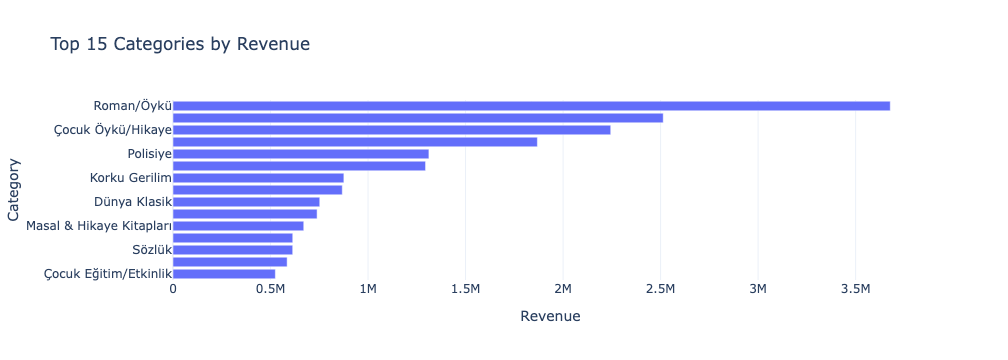

In [16]:

category_sales = (
    df_clean.groupby("Category", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(15)
)

fig = px.bar(
    category_sales,
    x="Revenue",
    y="Category",
    orientation="h",
    title="Top 15 Categories by Revenue"
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"},
    template="plotly_white"
)

fig.show()


In [17]:

# Save processed dataset for Streamlit

df_clean.to_parquet(
    "cleaned_data.parquet",
    index=False
)

print("Processed dataset saved successfully!")
print("Final Shape:", df_clean.shape)


Processed dataset saved successfully!
Final Shape: (664143, 21)


In [18]:

# Verify original price columns

sample = df.loc[
    df["Quantity"].isin([1, 2, 5, 10]),
    [
        "InvoiceNo",
        "StockCode",
        "Quantity",
        "NetPrice",
        "UnitPrice"
    ]
].sample(20, random_state=42)

display(sample)

# Check whether prices depend on quantity
print("\nMedian price by quantity:")

display(
    df.groupby("Quantity")[
        ["NetPrice", "UnitPrice"]
    ].median().head(15)
)


,InvoiceNo,StockCode,Quantity,NetPrice,UnitPrice
152948,BAD202000007791,9786059267144,1.00,11.52,18.00
641523,BSR202000018252,9789750842597,1.00,15.60,24.00
62198,BSR202000001441,9786051881843,1.00,8.40,14.00
343240,BAD202000015042,9789755705859,10.00,13.00,20.00
21334,BAD202000001145,9786059800617,1.00,13.44,21.00
230620,BSR202000005906,9789753637480,2.00,23.40,36.00
15416,BAD202000000829,9786057906540,5.00,12.10,22.00
313245,BSR202000008468,9786052951798,2.00,11.16,18.00
62804,BSR202000001433,9786059232227,1.00,22.62,39.00
303239,BAD202000013555,9786050935141,1.00,14.06,20.37



Median price by quantity:


,NetPrice,UnitPrice
Quantity,,
0.00,-159.21,159.21
1.00,15.40,25.00
2.00,15.00,25.00
3.00,14.49,24.00
4.00,14.40,23.00
5.00,13.68,22.00
6.00,13.64,22.00
7.00,13.64,22.00
8.00,14.00,22.00


In [19]:

# RFM Customer Segmentation

snapshot_date = (
    df_clean["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    df_clean.groupby("CustomerID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

rfm["Recency"] = (
    snapshot_date - rfm["LastPurchase"]
).dt.days

# Rank-based scores (1 = low, 5 = high)
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# Customer segments
rfm["Segment"] = np.select(
    [
        rfm["RFM_Score"] >= 13,
        rfm["RFM_Score"] >= 10,
        rfm["RFM_Score"] >= 7
    ],
    [
        "Champions",
        "Loyal Customers",
        "Potential Customers"
    ],
    default="At Risk"
)

print("RFM SEGMENTATION COMPLETED")

display(rfm.head())

print("\nCUSTOMER SEGMENTS")
display(rfm["Segment"].value_counts())


RFM SEGMENTATION COMPLETED


,CustomerID,LastPurchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score,Segment
0,A00001,2020-12-31,205,"116,492.93",1,5,5,5,15,Champions
1,A00001-01,2020-12-28,7,"2,764.96",4,4,3,3,10,Loyal Customers
2,A00003,2020-12-31,297,"234,392.27",1,5,5,5,15,Champions
3,A00004,2020-10-30,2,"2,871.00",63,2,1,3,6,At Risk
4,A00005,2020-04-01,13,"5,561.85",275,1,3,3,7,Potential Customers



CUSTOMER SEGMENTS


Segment
At Risk                383
Champions              287
Potential Customers    271
Loyal Customers        260
Name: count, dtype: int64

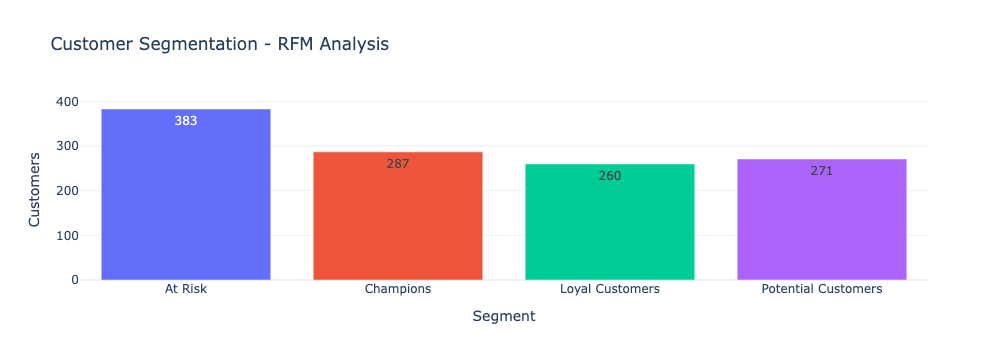

,Segment,Customers,Revenue,AverageRecency
0,At Risk,383,"331,168.30",204.69
1,Champions,287,"22,889,328.33",4.22
2,Loyal Customers,260,"4,266,628.69",24.97
3,Potential Customers,271,"2,092,834.91",73.94


In [20]:

segment_summary = (
    rfm.groupby("Segment", as_index=False)
    .agg(
        Customers=("CustomerID", "count"),
        Revenue=("Monetary", "sum"),
        AverageRecency=("Recency", "mean")
    )
)

fig = px.bar(
    segment_summary,
    x="Segment",
    y="Customers",
    color="Segment",
    title="Customer Segmentation - RFM Analysis",
    text="Customers"
)

fig.update_layout(
    template="plotly_white",
    showlegend=False
)

fig.show()

display(segment_summary)


In [21]:

rfm.to_parquet(
    "customer_segments.parquet",
    index=False
)

print("Customer segmentation file saved!")


Customer segmentation file saved!


In [22]:

%%writefile streamlit_app.py
import streamlit as st
import pandas as pd
import plotly.express as px
from pathlib import Path

st.set_page_config(
    page_title="B2B Sales Intelligence",
    page_icon="📊",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

@st.cache_data
def load_data():
    sales = pd.read_parquet(BASE_DIR / "cleaned_data.parquet")
    customers = pd.read_parquet(BASE_DIR / "customer_segments.parquet")
    sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
    return sales, customers

df, rfm = load_data()

st.title("📊 B2B Sales Intelligence")
st.caption("Sales, Marketing & Supply Chain Decision Support | 2020")

# SIDEBAR FILTERS
st.sidebar.header("Dashboard Filters")

date_range = st.sidebar.date_input(
    "Invoice Date",
    value=(df["InvoiceDate"].min().date(),
           df["InvoiceDate"].max().date()),
    min_value=df["InvoiceDate"].min().date(),
    max_value=df["InvoiceDate"].max().date()
)

categories = st.sidebar.multiselect(
    "Product Categories",
    sorted(df["Category"].dropna().unique().tolist())
)

cities = st.sidebar.multiselect(
    "Cities",
    sorted(df["City"].dropna().unique().tolist())
)

filtered = df.copy()

if len(date_range) == 2:
    start, end = date_range
    filtered = filtered[
        filtered["InvoiceDate"].dt.date.between(start, end)
    ]

if categories:
    filtered = filtered[filtered["Category"].isin(categories)]

if cities:
    filtered = filtered[filtered["City"].isin(cities)]

# KPI CALCULATIONS
revenue = filtered["Revenue"].sum()
orders = filtered["InvoiceNo"].nunique()
customers = filtered["CustomerID"].nunique()
units = filtered["Quantity"].sum()
aov = revenue / orders if orders else 0

tab1, tab2, tab3, tab4 = st.tabs([
    "📈 Sales Overview",
    "📚 Product Analytics",
    "👥 Customer Intelligence",
    "🚚 Supply Chain"
])

with tab1:
    st.subheader("Executive Sales Overview")

    c1, c2, c3, c4, c5 = st.columns(5)

    c1.metric("Net Revenue", f"{revenue:,.0f}")
    c2.metric("Orders", f"{orders:,}")
    c3.metric("Customers", f"{customers:,}")
    c4.metric("Units Sold", f"{units:,.0f}")
    c5.metric("Average Order Value", f"{aov:,.2f}")

    monthly = (
        filtered.groupby("YearMonth", as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Orders=("InvoiceNo", "nunique"))
        .sort_values("YearMonth")
    )

    fig = px.line(
        monthly,
        x="YearMonth",
        y="Revenue",
        markers=True,
        title="Monthly Revenue Trend"
    )
    st.plotly_chart(fig, use_container_width=True)

    if not monthly.empty:
        best = monthly.loc[monthly["Revenue"].idxmax()]
        worst = monthly.loc[monthly["Revenue"].idxmin()]

        st.info(
            f"Highest revenue: {best['YearMonth']} | "
            f"Lowest revenue: {worst['YearMonth']}"
        )

with tab2:
    st.subheader("Product and Category Performance")

    category = (
        filtered.groupby("Category", as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Units=("Quantity", "sum"))
        .sort_values("Revenue", ascending=False)
        .head(15)
    )

    fig = px.bar(
        category.sort_values("Revenue"),
        x="Revenue",
        y="Category",
        orientation="h",
        title="Top 15 Categories by Revenue",
        color="Revenue",
        color_continuous_scale="Blues"
    )

    st.plotly_chart(fig, use_container_width=True)

    products = (
        filtered.groupby(["StockCode", "Description"], as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Units=("Quantity", "sum"))
        .sort_values("Revenue", ascending=False)
        .head(20)
    )

    st.subheader("Top 20 Products")
    st.dataframe(products, use_container_width=True, hide_index=True)

with tab3:
    st.subheader("RFM Customer Segmentation")

    # Show segment distribution for customers
    # who appear in the current filtered data.
    selected_ids = filtered["CustomerID"].unique()
    current_rfm = rfm[rfm["CustomerID"].isin(selected_ids)]

    seg = (
        current_rfm.groupby("Segment", as_index=False)
        .agg(Customers=("CustomerID", "count"),
             RFM_Monetary=("Monetary", "sum"))
    )

    fig = px.bar(
        seg,
        x="Segment",
        y="Customers",
        color="Segment",
        text="Customers",
        title="Customer Segments"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.caption(
        "RFM scores are based on the full 2020 dataset. "
        "Segment monetary values are historical totals."
    )

    st.dataframe(
        seg,
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Marketing Recommendations")
    st.write("**Champions:** Prioritize retention and VIP benefits.")
    st.write("**Loyal Customers:** Develop cross-selling campaigns.")
    st.write("**Potential Customers:** Encourage repeat purchases.")
    st.write("**At Risk:** Test targeted reactivation campaigns.")

with tab4:
    st.subheader("Supply Chain and Demand Insights")

    city_demand = (
        filtered.groupby("City", as_index=False)
        .agg(Units=("Quantity", "sum"),
             Revenue=("Revenue", "sum"))
        .sort_values("Units", ascending=False)
        .head(15)
    )

    fig = px.bar(
        city_demand,
        x="City",
        y="Units",
        title="Top 15 Cities by Product Demand"
    )
    st.plotly_chart(fig, use_container_width=True)

    demand = (
        filtered.groupby("YearMonth", as_index=False)
        ["Quantity"].sum()
        .sort_values("YearMonth")
    )

    demand["RollingAverage3M"] = (
        demand["Quantity"].rolling(3).mean()
    )

    fig = px.line(
        demand,
        x="YearMonth",
        y=["Quantity", "RollingAverage3M"],
        markers=True,
        title="Monthly Demand and 3-Month Moving Average"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.info(
        "Demand trends can support inventory planning. "
        "Actual stock levels and lead times are not available."
    )

st.divider()
st.caption(
    "Source: B2B Transaction Dataset (2020). "
    "Revenue assumes NetPrice is a discounted unit price."
)


Writing streamlit_app.py


In [23]:

%%writefile requirements.txt
streamlit
pandas
numpy
plotly
pyarrow


Writing requirements.txt


In [24]:

from pathlib import Path

print("Current folder:", Path.cwd())

for filename in [
    "streamlit_app.py",
    "requirements.txt",
    "cleaned_data.parquet",
    "customer_segments.parquet"
]:
    print(filename, ":", Path(filename).exists())


Current folder: /Users/bahartamturk
streamlit_app.py : True
requirements.txt : True
cleaned_data.parquet : True
customer_segments.parquet : True


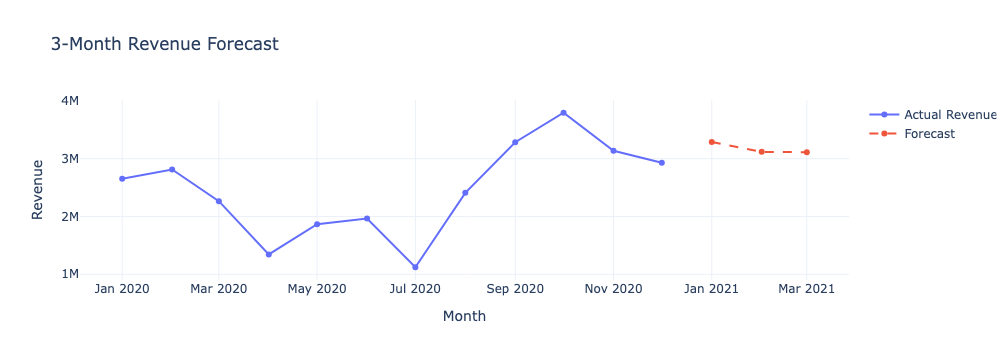

,Date,ForecastRevenue
0,2021-01-01,"3,287,245.11"
1,2021-02-01,"3,118,018.20"
2,2021-03-01,"3,111,753.29"


Forecast saved successfully!


In [25]:

# Simple sales forecasting using 3-month moving average

import pandas as pd
import plotly.graph_objects as go

monthly = (
    df_clean.groupby("YearMonth", as_index=False)
    ["Revenue"].sum()
    .sort_values("YearMonth")
)

monthly["Date"] = pd.to_datetime(monthly["YearMonth"])

# Forecast next 3 months recursively
history = monthly["Revenue"].tolist()
predictions = []

for i in range(3):
    forecast = sum(history[-3:]) / 3
    predictions.append(forecast)
    history.append(forecast)

future_dates = pd.date_range(
    start=monthly["Date"].max() + pd.DateOffset(months=1),
    periods=3,
    freq="MS"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "ForecastRevenue": predictions
})

# Visualize
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=monthly["Date"],
    y=monthly["Revenue"],
    mode="lines+markers",
    name="Actual Revenue"
))

fig.add_trace(go.Scatter(
    x=forecast_df["Date"],
    y=forecast_df["ForecastRevenue"],
    mode="lines+markers",
    name="Forecast",
    line=dict(dash="dash")
))

fig.update_layout(
    title="3-Month Revenue Forecast",
    xaxis_title="Month",
    yaxis_title="Revenue",
    template="plotly_white"
)

fig.show()

display(forecast_df)

forecast_df.to_parquet(
    "sales_forecast.parquet",
    index=False
)

print("Forecast saved successfully!")


In [26]:

from pathlib import Path

print("Forecast file exists:",
      Path("sales_forecast.parquet").exists())

display(pd.read_parquet("sales_forecast.parquet"))


Forecast file exists: True


,Date,ForecastRevenue
0,2021-01-01,"3,287,245.11"
1,2021-02-01,"3,118,018.20"
2,2021-03-01,"3,111,753.29"


In [27]:

# Add forecasting section to Streamlit

from pathlib import Path

app_path = Path("streamlit_app.py")

forecast_code = '''

# FORECASTING SECTION
st.divider()
st.header("🔮 Sales Forecasting")

forecast_df = pd.read_parquet(
    BASE_DIR / "sales_forecast.parquet"
)

historical = (
    df.groupby("YearMonth", as_index=False)
    ["Revenue"].sum()
    .sort_values("YearMonth")
)

historical["Date"] = pd.to_datetime(
    historical["YearMonth"]
)

import plotly.graph_objects as go

fig_forecast = go.Figure()

fig_forecast.add_trace(go.Scatter(
    x=historical["Date"],
    y=historical["Revenue"],
    mode="lines+markers",
    name="Historical Revenue"
))

fig_forecast.add_trace(go.Scatter(
    x=forecast_df["Date"],
    y=forecast_df["ForecastRevenue"],
    mode="lines+markers",
    name="Forecast",
    line=dict(dash="dash")
))

fig_forecast.update_layout(
    title="3-Month Revenue Forecast",
    xaxis_title="Month",
    yaxis_title="Revenue",
    template="plotly_dark"
)

st.plotly_chart(fig_forecast, use_container_width=True)

st.dataframe(
    forecast_df,
    use_container_width=True,
    hide_index=True
)

st.caption(
    "Forecasting method: Recursive 3-month moving average. "
    "Predictions are illustrative and based only on 2020 sales."
)
'''

content = app_path.read_text(encoding="utf-8")

if "# FORECASTING SECTION" not in content:
    with app_path.open("a", encoding="utf-8") as f:
        f.write(forecast_code)
    print("Forecasting section added successfully!")
else:
    print("Forecasting section already exists.")


Forecasting section added successfully!


In [28]:

from pathlib import Path
import shutil

source = Path.cwd()
project = source / "B2B_Streamlit_Project"
project.mkdir(exist_ok=True)

files = [
    "streamlit_app.py",
    "requirements.txt",
    "Data_Preprocessing.ipynb",
    "cleaned_data.parquet",
    "customer_segments.parquet",
    "sales_forecast.parquet"
]

for filename in files:
    shutil.copy2(source / filename, project / filename)

print("Project folder:", project)
for f in project.iterdir():
    print(f.name, round(f.stat().st_size / 1024 / 1024, 2), "MB")


Project folder: /Users/bahartamturk/B2B_Streamlit_Project
requirements.txt 0.0 MB
cleaned_data.parquet 17.86 MB
customer_segments.parquet 0.03 MB
streamlit_app.py 0.01 MB
sales_forecast.parquet 0.0 MB
Data_Preprocessing.ipynb 0.44 MB
